## EN3160 — Assignment 2
### Fitting and Alignment
**Student Name:** Deshan W. U.

**Index Number:** 230130E

In [2]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

Question 1

In [31]:
# Load image
im = cv.imread('a2images/the_berry_farms_sunflower_field.jpeg', cv.IMREAD_REDUCED_COLOR_4)
assert im is not None

# Get grayscale image
gray = cv.cvtColor(im, cv.COLOR_BGR2GRAY)

In [33]:
# Select range of sigma
sigma_values = np.linspace(1, 2, 4)
# Threhsold for blob detection
threshold = 0.35

# Store responses of each scale
blob_responses = []

for sigma in sigma_values:
    print(f"Processing scale with sigma = {sigma}")

    # Apply Gaussian blur
    gaussian_blur = cv.GaussianBlur(gray, (0, 0), sigma)
    # Compute Laplacian of Gaussian (LoG)
    laplacian = cv.Laplacian(gaussian_blur, cv.CV_64F)

    # Get absolute value
    blob_response = np.abs(laplacian)

    # Threshold the response and get contours
    mask = blob_response > threshold * blob_response.max()
    contours, _ = cv.findContours(mask.astype(np.uint8), cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)

    # Draw contours as circles
    for contour in contours:
        if len(contour) >= 5:
            # Get the center and radius of the enclosing circle from contour
            (center_x, center_y), radius = cv.minEnclosingCircle(contour)
            # Convert to integers
            center = (int(center_x), int(center_y))
            radius = int(radius)
            blob_responses.append((center, radius, sigma))

Processing scale with sigma = 1.0
Processing scale with sigma = 1.3333333333333333
Processing scale with sigma = 1.6666666666666665
Processing scale with sigma = 2.0


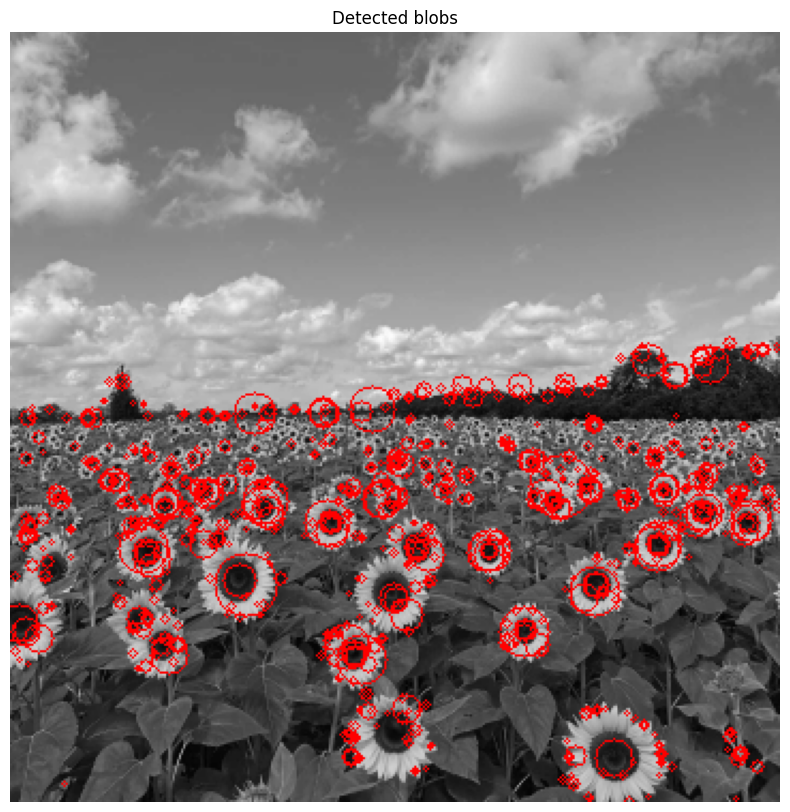

In [34]:
# Draw all detected circles with the specified line thickness
output = cv.cvtColor(gray, cv.COLOR_GRAY2BGR)
for blob in blob_responses:
    center, radius, _ = blob
    cv.circle(output, center, radius, (0, 0, 255), 1)

# Display the grayscale image with detected circles
plt.figure(figsize=(10, 10))
plt.imshow(cv.cvtColor(output, cv.COLOR_BGR2RGB), cmap='gray')
plt.axis('off')
plt.title('Detected blobs')
plt.show()

In [35]:
# Get largest circle
blobs_sorted = sorted(blob_responses, key=lambda x: x[1], reverse=True)
largest_blob = blobs_sorted[0]
center, radius, sigma = largest_blob

# Print largest circle details
print(f"Largest blob at : {center} with radius {radius} and sigma {sigma}")

Largest blob at : (110, 258) with radius 15 and sigma 2.0


The largest detected blob was located at **(110, 258)**, with a radius of **15 pixels** and a sigma value of **2.0 pixels**. The LoG-based blob detection was performed using four sigma values ranging from **1.0 to 2.0 pixels**: 1.00, 1.33, 1.67, and 2.00 pixels.


Question 2